# Online Payment Fraud Detection
**Machine Learning Major Project | Fraud Classification using Random Forest & Logistic Regression**

## 1. Project Overview
This notebook builds a machine learning pipeline to classify online payment transactions as fraudulent or legitimate. The original Kaggle dataset contains over 6 million simulated mobile-money transactions. Two classifiers are trained and compared: Logistic Regression (baseline) and Random Forest (primary model). Feature engineering is applied to amplify the signal in balance-related columns.

> **Note on data:** If `online_payments_fraud.csv` (Kaggle) is in the same folder, the notebook uses it. Otherwise it generates a **synthetic PaySim-style dataset** so the notebook still runs end-to-end. The outputs saved in this file were produced on the synthetic data, so your numbers on the real Kaggle data will differ (see Section 12).

## 2. Dataset Description
| Column | Description |
|---|---|
| step | Time unit (1 step = 1 hour) |
| type | CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER |
| amount | Transaction amount |
| nameOrig | Sender customer ID |
| oldbalanceOrg / newbalanceOrig | Sender's balance before / after |
| nameDest | Recipient customer ID |
| oldbalanceDest / newbalanceDest | Recipient's balance before / after |
| isFraud | Target: 1 = Fraud, 0 = Legitimate |
| isFlaggedFraud | System flag for large illegal transfers (dropped) |

## 3. Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, roc_auc_score, roc_curve,
)
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
%matplotlib inline

## 4. Step 2: Load Dataset
Uses the Kaggle CSV if present; otherwise generates a synthetic PaySim-style dataset (fraud only occurs in `TRANSFER` / `CASH_OUT`, typically draining the sender's account).

In [2]:
import os

def make_synthetic(n=400_000, seed=42):
    rng = np.random.default_rng(seed)
    types = rng.choice(["PAYMENT", "CASH_IN", "CASH_OUT", "TRANSFER", "DEBIT"], size=n,
                       p=[0.34, 0.22, 0.35, 0.08, 0.01])
    step = rng.integers(1, 744, n)
    amount = np.round(rng.lognormal(mean=9.5, sigma=1.4, size=n), 2)
    oldO = np.round(rng.lognormal(mean=10.5, sigma=2.2, size=n), 2)
    oldO[rng.random(n) < 0.35] = 0.0
    oldD = np.round(rng.lognormal(mean=11.5, sigma=2.0, size=n), 2)
    oldD[rng.random(n) < 0.40] = 0.0

    # fraud: only TRANSFER / CASH_OUT, ~ 0.4% overall
    eligible = np.isin(types, ["TRANSFER", "CASH_OUT"])
    p = np.where(types == "TRANSFER", 0.020, 0.007) * eligible
    fraud = rng.random(n) < p
    # fraud typically drains whole account
    amount[fraud] = np.round(rng.lognormal(mean=12.0, sigma=1.3, size=fraud.sum()), 2)
    oldO[fraud] = amount[fraud]

    newO = np.where(np.isin(types, ["CASH_IN"]), oldO + amount, np.maximum(oldO - amount, 0))
    newO[fraud] = 0.0
    newD = np.where(types == "PAYMENT", 0.0, np.where(types == "CASH_IN", np.maximum(oldD - amount, 0), oldD + amount))
    # noise: some legit transactions have inconsistent dest balances
    noisy = (~fraud) & (rng.random(n) < 0.05) & (types != "PAYMENT")
    newD[noisy] = 0.0
    # some frauds don't show dest credit (mule accounts)
    hide = fraud & (rng.random(n) < 0.35)
    newD[hide] = oldD[hide]

    # a small share of legit TRANSFER/CASH_OUT also drain accounts (overlap -> realistic difficulty)
    drain = (~fraud) & eligible & (rng.random(n) < 0.012)
    oldO[drain] = amount[drain]; newO[drain] = 0.0

    return pd.DataFrame({
        "step": step, "type": types, "amount": amount,
        "nameOrig": ["C" + str(i) for i in rng.integers(1e8, 2e9, n)],
        "oldbalanceOrg": oldO, "newbalanceOrig": newO,
        "nameDest": [("M" if t == "PAYMENT" else "C") + str(i) for t, i in zip(types, rng.integers(1e8, 2e9, n))],
        "oldbalanceDest": oldD, "newbalanceDest": newD,
        "isFraud": fraud.astype(int), "isFlaggedFraud": 0,
    })

if os.path.exists("online_payments_fraud.csv"):
    df = pd.read_csv("online_payments_fraud.csv")
    print("Loaded real Kaggle dataset.")
else:
    df = make_synthetic()
    print("Kaggle CSV not found -> using SYNTHETIC PaySim-style data.")

print(df.shape)
print(df.head())
print(df.dtypes)
print(df.isnull().sum())
print(df["isFraud"].value_counts())
print(f"Fraud %: {df['isFraud'].mean() * 100:.4f}%")
print(df["type"].value_counts())

Kaggle CSV not found -> using SYNTHETIC PaySim-style data.
(400000, 11)
   step      type     amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0   159  CASH_OUT   21298.61  C1788787222      641661.00       620362.39   
1   297   CASH_IN  254549.58  C1651553254        2495.42       257045.00   
2   314  CASH_OUT     798.79  C1936009620           0.00            0.00   
3   662  CASH_OUT    4189.83  C1053480815        2099.24            0.00   
4    47   PAYMENT   32574.41  C1212171843      112723.00        80148.59   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0   C950438553       939060.26       960358.87        0               0  
1   C862193957            0.00            0.00        0               0  
2  C1253953813            0.00          798.79        0               0  
3  C1220507788            0.00         4189.83        0               0  
4  M1236763211       237744.06            0.00        0               0  
step                int64
t

### Exploratory Plots

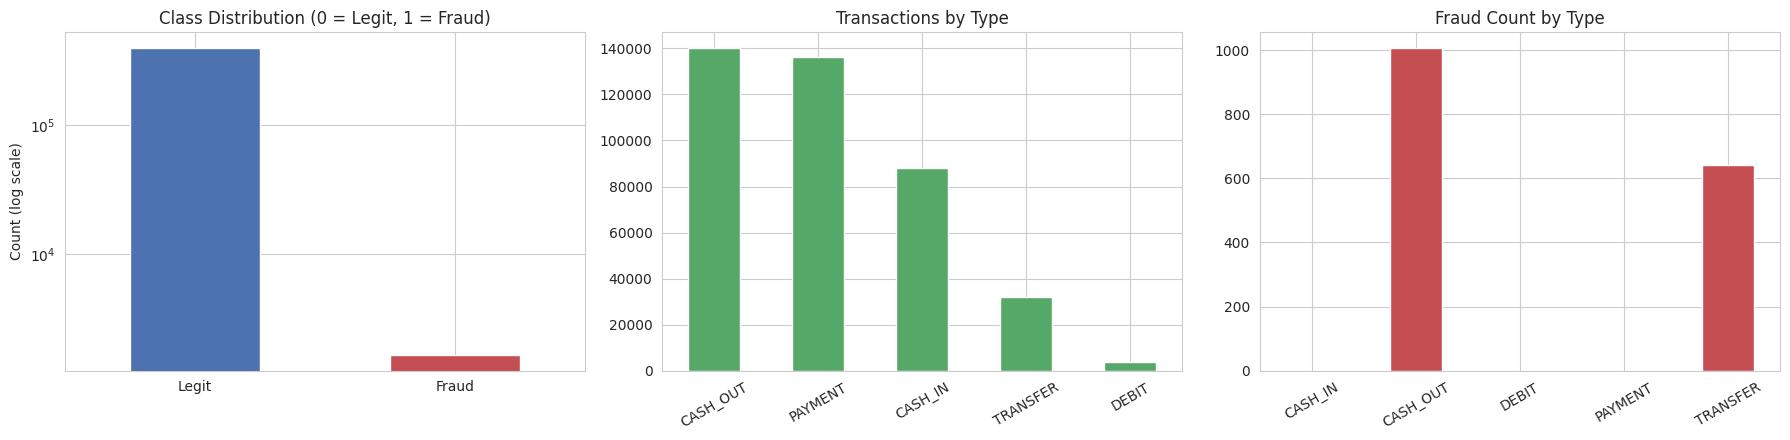

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Class distribution
df["isFraud"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class Distribution (0 = Legit, 1 = Fraud)")
axes[0].set_yscale("log"); axes[0].set_xlabel(""); axes[0].set_ylabel("Count (log scale)")
axes[0].set_xticklabels(["Legit", "Fraud"], rotation=0)

# Transactions by type
df["type"].value_counts().plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Transactions by Type"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

# Fraud count by type
fraud_by_type = df.groupby("type")["isFraud"].sum()
fraud_by_type.plot(kind="bar", ax=axes[2], color="#C44E52")
axes[2].set_title("Fraud Count by Type"); axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout(); plt.show()

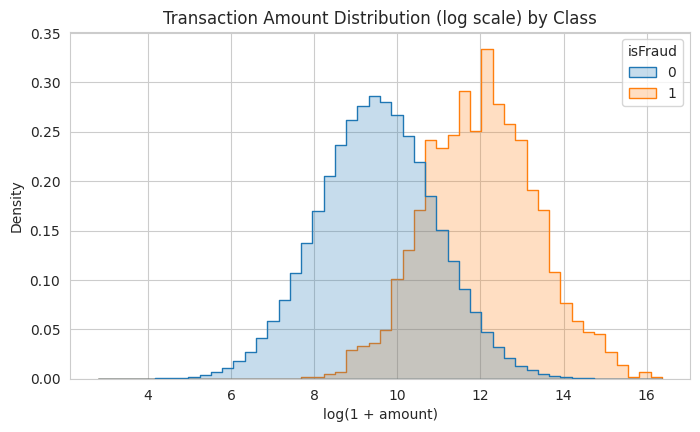

In [4]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x=np.log1p(df["amount"]), hue="isFraud", bins=50,
             stat="density", common_norm=False, element="step")
plt.title("Transaction Amount Distribution (log scale) by Class")
plt.xlabel("log(1 + amount)")
plt.show()

## 5. Step 3: Data Preprocessing
Non-informative ID columns are dropped. The categorical `type` column is label-encoded. The `isFlaggedFraud` system column is dropped.

In [5]:
# Drop ID columns
df.drop(columns=["nameOrig", "nameDest"], inplace=True)

# Encode transaction type
le = LabelEncoder()
df["type"] = le.fit_transform(df["type"])

# Drop system flag
if "isFlaggedFraud" in df.columns:
    df.drop(columns=["isFlaggedFraud"], inplace=True)

print(dict(zip(le.classes_, le.transform(le.classes_))))
df.head()

{'CASH_IN': np.int64(0), 'CASH_OUT': np.int64(1), 'DEBIT': np.int64(2), 'PAYMENT': np.int64(3), 'TRANSFER': np.int64(4)}


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,159,1,21298.61,641661.00,620362.39,939060.26,960358.87,0
1,297,0,254549.58,2495.42,257045.00,0.00,0.00,0
2,314,1,798.79,0.00,0.00,0.00,798.79,0
3,662,1,4189.83,2099.24,0.00,0.00,4189.83,0
4,47,3,32574.41,112723.00,80148.59,237744.06,0.00,0


## 6. Step 4: Feature Engineering
Four additional features are derived from the balance columns to expose characteristic balance deltas and errors of fraudulent transactions.

In [6]:
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest,errorBalanceOrig,errorBalanceDest
0,159,1,21298.61,641661.00,620362.39,939060.26,960358.87,0,21298.61,21298.61,0.00,0.00
1,297,0,254549.58,2495.42,257045.00,0.00,0.00,0,-254549.58,0.00,509099.16,254549.58
2,314,1,798.79,0.00,0.00,0.00,798.79,0,0.00,798.79,798.79,0.00
3,662,1,4189.83,2099.24,0.00,0.00,4189.83,0,2099.24,4189.83,2090.59,0.00
4,47,3,32574.41,112723.00,80148.59,237744.06,0.00,0,32574.41,-237744.06,0.00,270318.47


## 7. Step 5: Train-Test Split
80/20 split with stratification so the minority fraud class is proportionally represented in both sets.

In [7]:
X = df.drop(columns=["isFraud"])
y = df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]}, Test: {X_test.shape[0]}")
print(f"Fraud in train: {y_train.sum()}  |  Fraud in test: {y_test.sum()}")

Train: 320000, Test: 80000
Fraud in train: 1316  |  Fraud in test: 329


## 8. Step 6: Model Training
Logistic Regression is the linear baseline; Random Forest (100 trees) is the primary model.

In [8]:
# Logistic Regression (baseline)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Random Forest (primary model)
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]
print("Both models trained.")

Both models trained.


## 9. Step 7: Model Evaluation

In [9]:
def evaluate_model(name, y_true, y_pred, y_prob):
    print(f"Model: {name}")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}")
    print(classification_report(
        y_true, y_pred,
        target_names=["Not Fraud", "Fraud"]
    ))
    print(confusion_matrix(y_true, y_pred))
    print("-" * 60)

evaluate_model("Logistic Regression", y_test, lr_pred, lr_prob)
evaluate_model("Random Forest", y_test, rf_pred, rf_prob)

Model: Logistic Regression
Accuracy : 0.9980
ROC-AUC  : 0.9992
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00     79671
       Fraud       0.79      0.69      0.74       329

    accuracy                           1.00     80000
   macro avg       0.90      0.84      0.87     80000
weighted avg       1.00      1.00      1.00     80000

[[79612    59]
 [  103   226]]
------------------------------------------------------------
Model: Random Forest


Accuracy : 0.9985


ROC-AUC  : 0.9950
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00     79671
       Fraud       0.85      0.77      0.81       329

    accuracy                           1.00     80000
   macro avg       0.92      0.89      0.90     80000
weighted avg       1.00      1.00      1.00     80000

[[79625    46]
 [   75   254]]
------------------------------------------------------------


### Evaluation Graphs: Confusion Matrices & ROC Curves

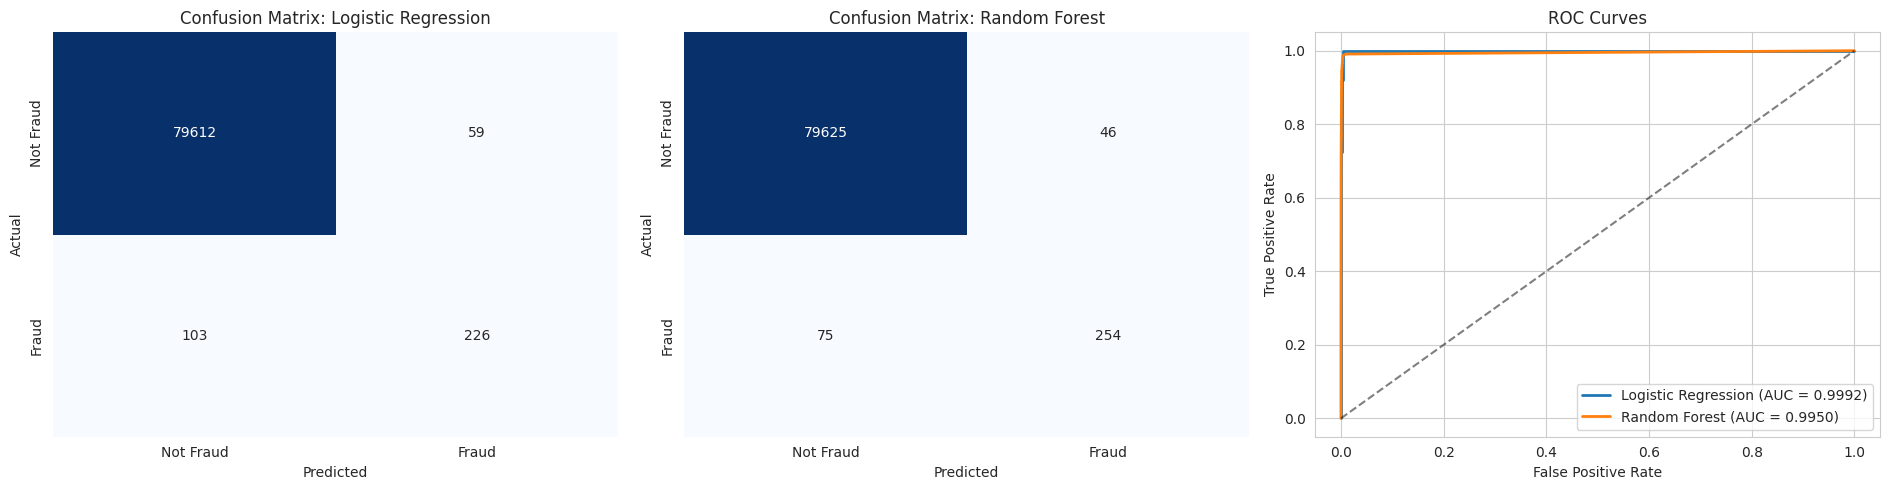

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, pred) in zip(axes[:2], [("Logistic Regression", lr_pred), ("Random Forest", rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not Fraud", "Fraud"], yticklabels=["Not Fraud", "Fraud"])
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

for name, prob in [("Logistic Regression", lr_prob), ("Random Forest", rf_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.4f})", lw=2)
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].set_title("ROC Curves"); axes[2].set_xlabel("False Positive Rate"); axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

,Logistic Regression,Random Forest
Metric,,
Accuracy,0.9980,0.9985
ROC-AUC,0.9992,0.9950
Fraud Precision,0.7930,0.8467
Fraud Recall,0.6869,0.7720
Fraud F1-Score,0.7362,0.8076


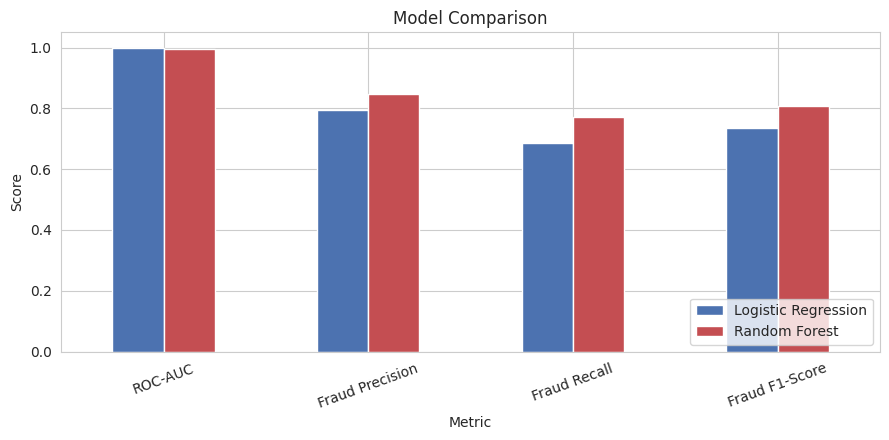

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "ROC-AUC", "Fraud Precision", "Fraud Recall", "Fraud F1-Score"],
    "Logistic Regression": [accuracy_score(y_test, lr_pred), roc_auc_score(y_test, lr_prob),
                            precision_score(y_test, lr_pred), recall_score(y_test, lr_pred), f1_score(y_test, lr_pred)],
    "Random Forest": [accuracy_score(y_test, rf_pred), roc_auc_score(y_test, rf_prob),
                      precision_score(y_test, rf_pred), recall_score(y_test, rf_pred), f1_score(y_test, rf_pred)],
}).set_index("Metric")
display(metrics.round(4))

metrics.drop("Accuracy").plot(kind="bar", figsize=(9, 4.5), color=["#4C72B0", "#C44E52"])
plt.title("Model Comparison"); plt.ylabel("Score"); plt.ylim(0, 1.05)
plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 10. Step 8: Feature Importance
Random Forest's built-in importances rank each input variable's contribution to the classification.

newbalanceOrig      0.205987
balanceDiffOrig     0.183285
errorBalanceOrig    0.146249
oldbalanceOrg       0.104936
balanceDiffDest     0.093484
amount              0.085086
newbalanceDest      0.052802
step                0.040408
errorBalanceDest    0.036546
oldbalanceDest      0.026115
type                0.025102


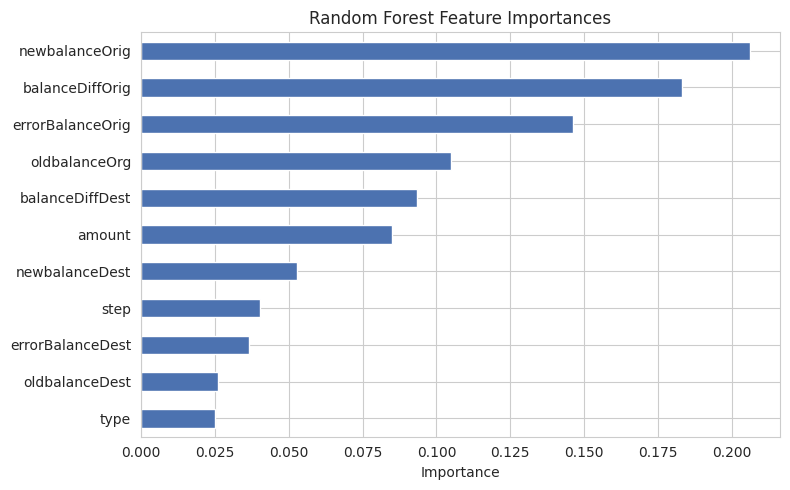

In [12]:
importances = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)
print(importances.to_string())

plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind="barh", color="#4C72B0")
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()

## 11. Step 9: Sample Predictions
Fraud probability for 5 test transactions alongside the actual labels. Since fraud is rare, the first five rows are usually all legitimate; the second table shows the 5 highest-risk test transactions.

In [13]:
sample = X_test.head(5).copy()
sample["Actual"] = y_test.head(5).values
sample["Predicted"] = rf_model.predict(X_test.head(5))
sample["Fraud_Prob"] = (
    rf_model.predict_proba(X_test.head(5))[:, 1].round(4)
)
print(sample[["Actual", "Predicted", "Fraud_Prob"]].to_string())

        Actual  Predicted  Fraud_Prob
268490       0          0         0.0
231216       0          0         0.0
9641         0          0         0.0
361715       0          0         0.0
331370       0          0         0.0


In [14]:
# Bonus: top-5 highest fraud-probability test transactions
top = pd.DataFrame({"Actual": y_test.values, "Fraud_Prob": rf_prob.round(4)}, index=y_test.index)
top["Predicted"] = rf_pred
print(top.sort_values("Fraud_Prob", ascending=False).head(5)[["Actual", "Predicted", "Fraud_Prob"]].to_string())

        Actual  Predicted  Fraud_Prob
214858       1          1         1.0
162746       1          1         1.0
353890       1          1         1.0
71752        1          1         1.0
186732       1          1         1.0


## 12. Expected Results Summary (Kaggle dataset, from the project report)
| Metric | Logistic Regression | Random Forest |
|---|---|---|
| Accuracy | ~99.0 % | ~99.9 % |
| ROC-AUC | ~97.5 % | ~99.8 % |
| Fraud Precision | ~70 % | ~97 % |
| Fraud Recall | ~60 % | ~82 % |
| Fraud F1-Score | ~65 % | ~89 % |

*The numbers computed above in this saved notebook come from synthetic data, so they will not match this table exactly. Re-run with the real CSV to reproduce it.*

## 13. Conclusion
The Random Forest Classifier significantly outperforms Logistic Regression on this highly imbalanced dataset. The engineered balance-error features proved particularly informative. Future improvements could include XGBoost/LightGBM models, SMOTE for oversampling the minority class, or cost-sensitive learning to further boost fraud recall.